In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

DATA_DIR = Path(
    "/Users/manyamoonat/pbl sem5/Euphorbia_Augmented_3000"
)

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42
EPOCHS = 30

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Dataset exists:", DATA_DIR.exists())

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        print(folder.name)

TensorFlow: 2.16.2
Dataset exists: True
.ipynb_checkpoints
diseased
healthy


In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

class_names = train_ds.class_names

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=class_names,
    shuffle=True
)

print("Class order:", class_names)

Found 3214 files belonging to 2 classes.
Using 2250 files for training.
Found 3214 files belonging to 2 classes.
Using 964 files for validation.
Class order: ['diseased', 'healthy']


2026-10-23 09:48:29.812325: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-23 09:48:29.812356: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-23 09:48:29.812359: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-23 09:48:29.812377: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-23 09:48:29.812390: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [3]:
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(ds, training=False):
    ds = ds.map(
        lambda images, labels: (
            tf.cast(images, tf.float32) / 255.0,
            labels
        ),
        num_parallel_calls=AUTOTUNE
    )

    if training:
        ds = ds.shuffle(500, seed=SEED)

    return ds.prefetch(AUTOTUNE)

train_ds = prepare_dataset(train_ds, training=True)
val_ds = prepare_dataset(val_ds)

print("Datasets prepared.")

Datasets prepared.


In [4]:
from tensorflow.keras import layers, models, regularizers

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Augmentation applied during training only
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    layers.Conv2D(
        32, 3, padding="same",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),

    layers.Conv2D(
        64, 3, padding="same",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(
        128, 3, padding="same",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [5]:
OUTPUT_DIR = Path("custom_cnn_augmented_results")
OUTPUT_DIR.mkdir(exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / "best_custom_cnn.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30


2026-10-23 09:49:04.602536: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.
2026-10-23 09:49:15.103506: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:17: Filling up shuffle buffer (this may take a while): 72 of 500
2026-10-23 09:49:25.228058: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5567 - loss: 0.9455 - precision: 0.6264 - recall: 0.6707 
Epoch 1: val_loss improved from None to 0.80024, saving model to custom_cnn_augmented_results/best_custom_cnn.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - accuracy: 0.5800 - loss: 0.8812 - precision: 0.6371 - recall: 0.7230 - val_accuracy: 0.6006 - val_loss: 0.8002 - val_precision: 0.6006 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 2/30


2026-10-23 09:49:55.838118: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:17: Filling up shuffle buffer (this may take a while): 65 of 500


  2/141 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.5469 - loss: 0.8565 - precision: 0.6012 - recall: 0.7111 

...

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6874 - loss: 0.6585 - precision: 0.7118 - recall: 0.8214
Epoch 14: val_loss did not improve from 0.67831
141/141 ━━━━━━━━━━━━━━━━━━━━ 42s 132ms/step - accuracy: 0.6929 - loss: 0.6578 - precision: 0.7212 - recall: 0.8090 - val_accuracy: 0.6162 - val_loss: 0.9503 - val_precision: 0.6113 - val_recall: 0.9914 - learning_rate: 1.5000e-04
Epoch 15/30


2026-10-23 10:07:39.957167: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:450] ShuffleDatasetV3:17: Filling up shuffle buffer (this may take a while): 60 of 500


  1/141 ━━━━━━━━━━━━━━━━━━━━ 54:17 23s/step - accuracy: 0.6875 - loss: 0.8088 - precision: 0.6364 - recall: 0.8750

2026-10-23 10:07:52.974809: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:480] Shuffle buffer filled.


141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6964 - loss: 0.6801 - precision: 0.7253 - recall: 0.8071
Epoch 15: val_loss did not improve from 0.67831

Epoch 15: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
141/141 ━━━━━━━━━━━━━━━━━━━━ 41s 127ms/step - accuracy: 0.6893 - loss: 0.6676 - precision: 0.7207 - recall: 0.8010 - val_accuracy: 0.6027 - val_loss: 1.0162 - val_precision: 0.6019 - val_recall: 1.0000 - learning_rate: 1.5000e-04
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 9.


NameError: name 'history' is not defined

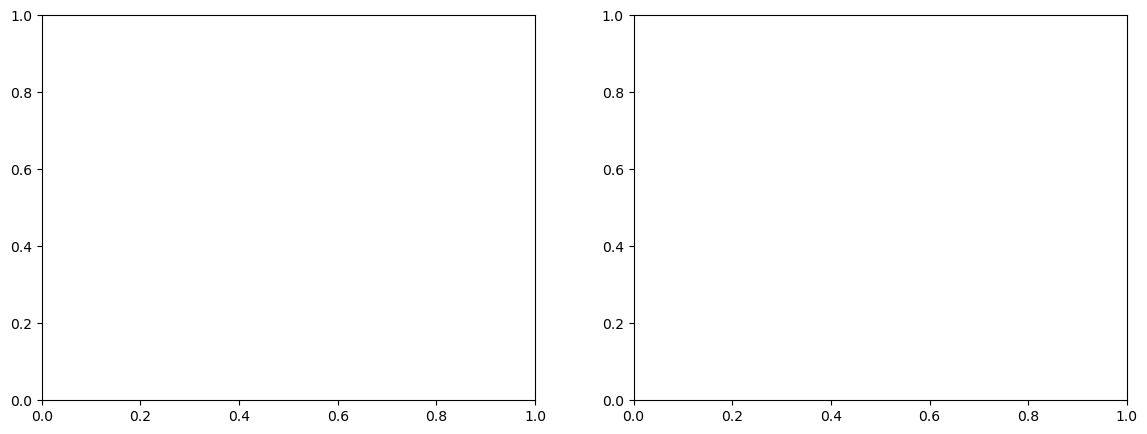

In [9]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy/loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [10]:
import os
from pathlib import Path

for path in [
    "custom_cnn_augmented_results/best_custom_cnn.keras",
    "custom_cnn_augmented_results/training_history.json",
    "custom_cnn_results"
]:
    print(path, "->", os.path.exists(path))

custom_cnn_augmented_results/best_custom_cnn.keras -> True
custom_cnn_augmented_results/training_history.json -> True
custom_cnn_results -> True


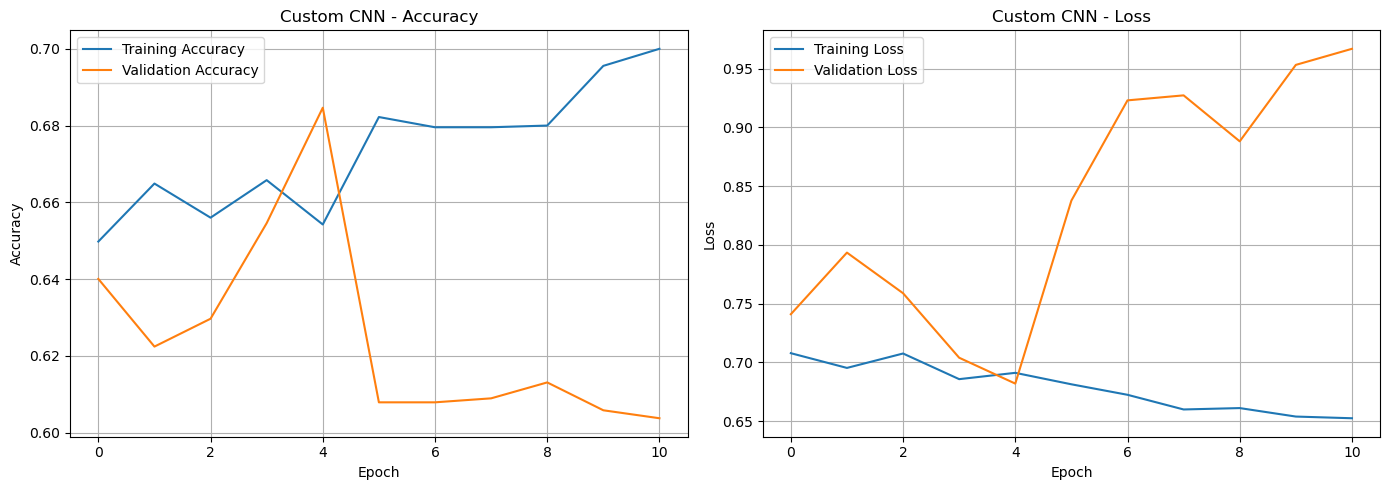

Best training accuracy: 70.00%
Best validation accuracy: 68.46%


In [11]:
import json
import matplotlib.pyplot as plt

history_path = "custom_cnn_augmented_results/training_history.json"

with open(history_path, "r") as f:
    history_data = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_data["accuracy"], label="Training Accuracy")
axes[0].plot(history_data["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_data["loss"], label="Training Loss")
axes[1].plot(history_data["val_loss"], label="Validation Loss")
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("custom_cnn_training_graphs.png", dpi=300)
plt.show()

print("Best training accuracy:",
      f"{max(history_data['accuracy']) * 100:.2f}%")
print("Best validation accuracy:",
      f"{max(history_data['val_accuracy']) * 100:.2f}%")

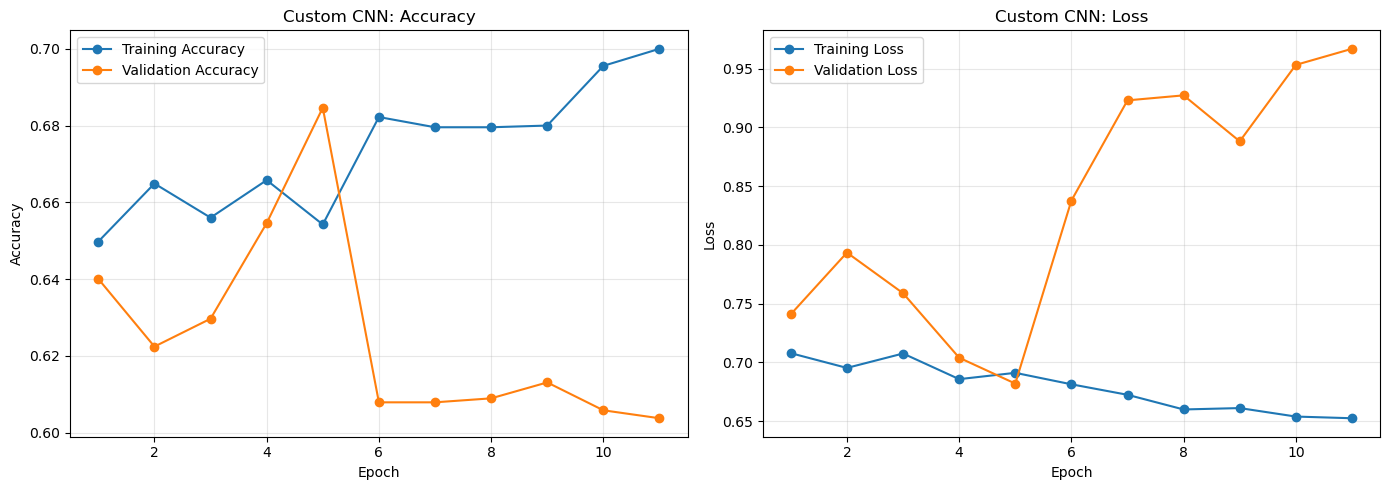

Best training accuracy: 70.00%
Best validation accuracy: 68.46%
Graphs saved to custom_cnn_results/custom_cnn_training_graphs.png


In [12]:
import json
import os
import matplotlib.pyplot as plt

history_path = "custom_cnn_augmented_results/training_history.json"

with open(history_path, "r") as f:
    history_data = json.load(f)

os.makedirs("custom_cnn_results", exist_ok=True)

epochs = range(1, len(history_data["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(epochs, history_data["accuracy"],
             marker="o", label="Training Accuracy")
axes[0].plot(epochs, history_data["val_accuracy"],
             marker="o", label="Validation Accuracy")
axes[0].set_title("Custom CNN: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss graph
axes[1].plot(epochs, history_data["loss"],
             marker="o", label="Training Loss")
axes[1].plot(epochs, history_data["val_loss"],
             marker="o", label="Validation Loss")
axes[1].set_title("Custom CNN: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "custom_cnn_results/custom_cnn_training_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best training accuracy:",
      f"{max(history_data['accuracy']) * 100:.2f}%")
print("Best validation accuracy:",
      f"{max(history_data['val_accuracy']) * 100:.2f}%")
print("Graphs saved to custom_cnn_results/custom_cnn_training_graphs.png")

In [13]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "custom_cnn_augmented_results/best_custom_cnn.keras"
)

model.summary()

2026-10-23 11:03:04.046506: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-23 11:03:04.046521: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-23 11:03:04.046524: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-23 11:03:04.046537: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-23 11:03:04.046544: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 331,461 (1.26 MB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 220,676 (862.02 KB)

In [14]:
TEST_DIR = "/Users/manyamoonat/pbl sem5/Euphorbia_Split/test"

IMG_SIZE = (128, 128)
BATCH_SIZE = 16

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="binary"
)

print("Test class order:", test_ds.class_names)

test_loss, test_accuracy, test_precision, test_recall = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Test Precision: {test_precision * 100:.2f}%")
print(f"Test Recall:    {test_recall * 100:.2f}%")
print(f"Test Loss:      {test_loss:.4f}")

Found 49 files belonging to 2 classes.
Test class order: ['diseased', 'healthy']


2026-10-23 11:03:17.711768: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 289ms/step - accuracy: 0.6735 - loss: 59.1827 - precision: 0.6667 - recall: 0.9333      
Test Accuracy:  67.35%
Test Precision: 66.67%
Test Recall:    93.33%
Test Loss:      59.1827


In [15]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score
)

y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds, verbose=1).ravel()

print("Prediction probability range:",
      np.min(y_prob), "to", np.max(y_prob))
print("First 10 probabilities:", np.round(y_prob[:10], 4))
print("First 10 true labels:", y_true[:10])

2026-10-23 11:04:13.344048: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step 
Prediction probability range: 0.0 to 1.0
First 10 probabilities: [1.     1.     1.     1.     0.     1.     1.     0.0077 1.     1.    ]
First 10 true labels: [0 0 0 0 0 0 0 0 0 0]


              precision    recall  f1-score   support

    diseased     0.7143    0.2632    0.3846        19
     healthy     0.6667    0.9333    0.7778        30

    accuracy                         0.6735        49
   macro avg     0.6905    0.5982    0.5812        49
weighted avg     0.6851    0.6735    0.6253        49



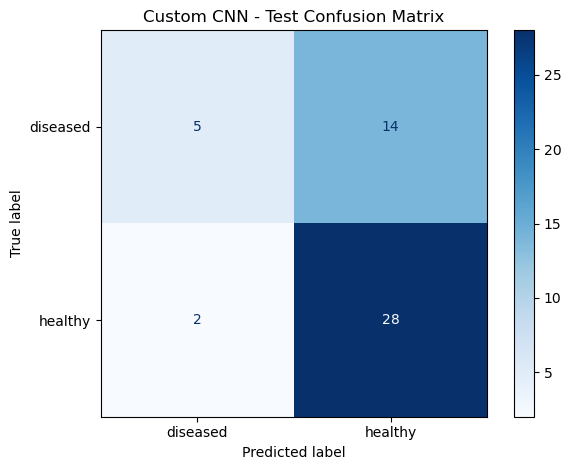

F1-score: 0.7778


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=test_ds.class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_ds.class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Custom CNN - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "custom_cnn_results/custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))

In [17]:
print("Model output shape:", model.output_shape)
print("Compiled loss:", model.loss)
print("Compiled metrics:", model.metrics_names)
print("Test labels:", np.unique(y_true, return_counts=True))

Model output shape: (None, 1)
Compiled loss: binary_crossentropy
Compiled metrics: ['loss', 'compile_metrics']
Test labels: (array([0, 1]), array([19, 30]))
